# Extended Data Figure 2. Sensitivity of simulated TCN responses to alternative transition coefficients

In [1]:
OUTPUT_NAME="Extended_data_figure_2"
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.environ.setdefault("SIM_RUN_MODE", "production")
%run ./simulation_core.ipynb
plt.rcParams.update(PLOT_STYLE)
OUTPUT_ROOT, FIGURE_DIR, SOURCE_DIR = make_output_dirs(OUTPUT_NAME)
MAX_PCN_TEST = 100
PRIMARY = {c.condition: c for c in standard_configurations(MAX_PCN_TEST)}

def baseline_check():
    assert np.isclose(PRIMARY["transposition off"].kappa_f, TRANSITIONS.kappa_f_off)
    assert np.isclose(PRIMARY["transposition on"].kappa_b, TRANSITIONS.kappa_b_on)
    assert np.isclose(PRIMARY["transposition on + PCN dynamics"].kappa_f, TRANSITIONS.kappa_f_pcn)
    assert CONSECUTIVE_CONVERGED_CYCLES == 8
    assert MIN_CONVERGENCE_CYCLES == 60
    assert RELAXED_DAYS_PER_CYCLE == 5 and SELECTED_DAYS_PER_CYCLE == 2
    assert np.isclose(PASSAGE_DILUTION_FACTOR, 30000)

baseline_check()
print("Core and Figure 2 configuration checks passed; mode:", RUN_MODE)
COEFFICIENT_SETS = [
    ("Original", 1.0, 1.0),
    ("Uniform", 2.0, 2.0),
    ("Forward-enhanced", 2.0, 1.0),
    ("Strong forward-enhanced", 2.0, 0.5),
]
CONFIG_ORDER = tuple(c.condition for c in standard_configurations(MAX_PCN_TEST))
assert len(CONFIG_ORDER) == 3
R2_FIXED, R2_PERIODIC, R2_CONFIGS = {}, {}, {}
R2_RATE_ROWS = []
for label, sf, sb in COEFFICIENT_SETS:
    for condition in CONFIG_ORDER:
        base = PRIMARY[condition]
        cfg = make_configuration(
            MAX_PCN_TEST, condition=condition,
            kappa_f=sf * base.kappa_f,
            kappa_b=sb * base.kappa_b,
            lower_forward_rate=base.lower_forward_rate,
            setting_label=f"R2 {label}: f={sf:g}, b={sb:g}",
        )
        assert_generator_valid(transition_matrix(MAX_PCN_TEST, cfg))
        R2_CONFIGS[(label, condition)] = cfg
        for phase, days, init in (
            ("loss", RELAXED_DAYS_PER_CYCLE, fixed_loss_initial_state(MAX_PCN_TEST)),
            ("gain", SELECTED_DAYS_PER_CYCLE, fixed_gain_initial_state(MAX_PCN_TEST)),
        ):
            frame, _, _, _ = simulate_phase(
                MAX_PCN_TEST, cfg, phase=phase, duration_days=days,
                initial_state=init.copy(), record_trajectory=True,
            )
            R2_FIXED[(label, condition, phase)] = frame
        conv = converge_periodic_state(
            MAX_PCN_TEST, cfg, periodic_initial_state(MAX_PCN_TEST)
        )
        metrics = periodic_metrics(
            conv["TCN_low"], conv["TCN_high"],
            conv["minimum_daily_prepassage_density"],
            converged=conv["converged"],
            population_extinct=conv["population_extinct"],
        )
        R2_RATE_ROWS.append(dict(
            coefficient_set=label, forward_multiplier=sf, backward_multiplier=sb,
            condition=condition, kappa_f=cfg.kappa_f, kappa_b=cfg.kappa_b,
            lower_forward_rate=cfg.lower_forward_rate,
            converged=conv["converged"],
            TCN_low=conv["TCN_low"], TCN_high=conv["TCN_high"], **metrics,
        ))
        if conv["converged"]:
            frame, _ = simulate_post_convergence_cycles(
                MAX_PCN_TEST, cfg, conv["state"]
            )
            R2_PERIODIC[(label, condition)] = frame

R2_RATES = pd.DataFrame(R2_RATE_ROWS)
assert len(R2_RATES) == len(COEFFICIENT_SETS) * len(CONFIG_ORDER)
assert (R2_RATES["kappa_f"] > 0).all() and (R2_RATES["kappa_b"] > 0).all()
print(R2_RATES[["coefficient_set", "condition", "converged", "response_valid", "loss_rate", "gain_rate"]].to_string(index=False))
export_table(R2_RATES, "Extended_data_figure_2_rates.csv", SOURCE_DIR)


Core and Figure 2 configuration checks passed; mode: production
        coefficient_set                       condition  converged  response_valid  loss_rate  gain_rate
               Original               transposition off       True            True   0.019548   0.048870
               Original                transposition on       True            True   0.036810   0.092024
               Original transposition on + PCN dynamics       True            True   0.048884   0.122211
                Uniform               transposition off       True            True   0.009015   0.022537
                Uniform                transposition on       True            True   0.032435   0.081087
                Uniform transposition on + PCN dynamics       True            True   0.050447   0.126117
       Forward-enhanced               transposition off       True            True   0.030179   0.075448
       Forward-enhanced                transposition on       True            True   0.054304   

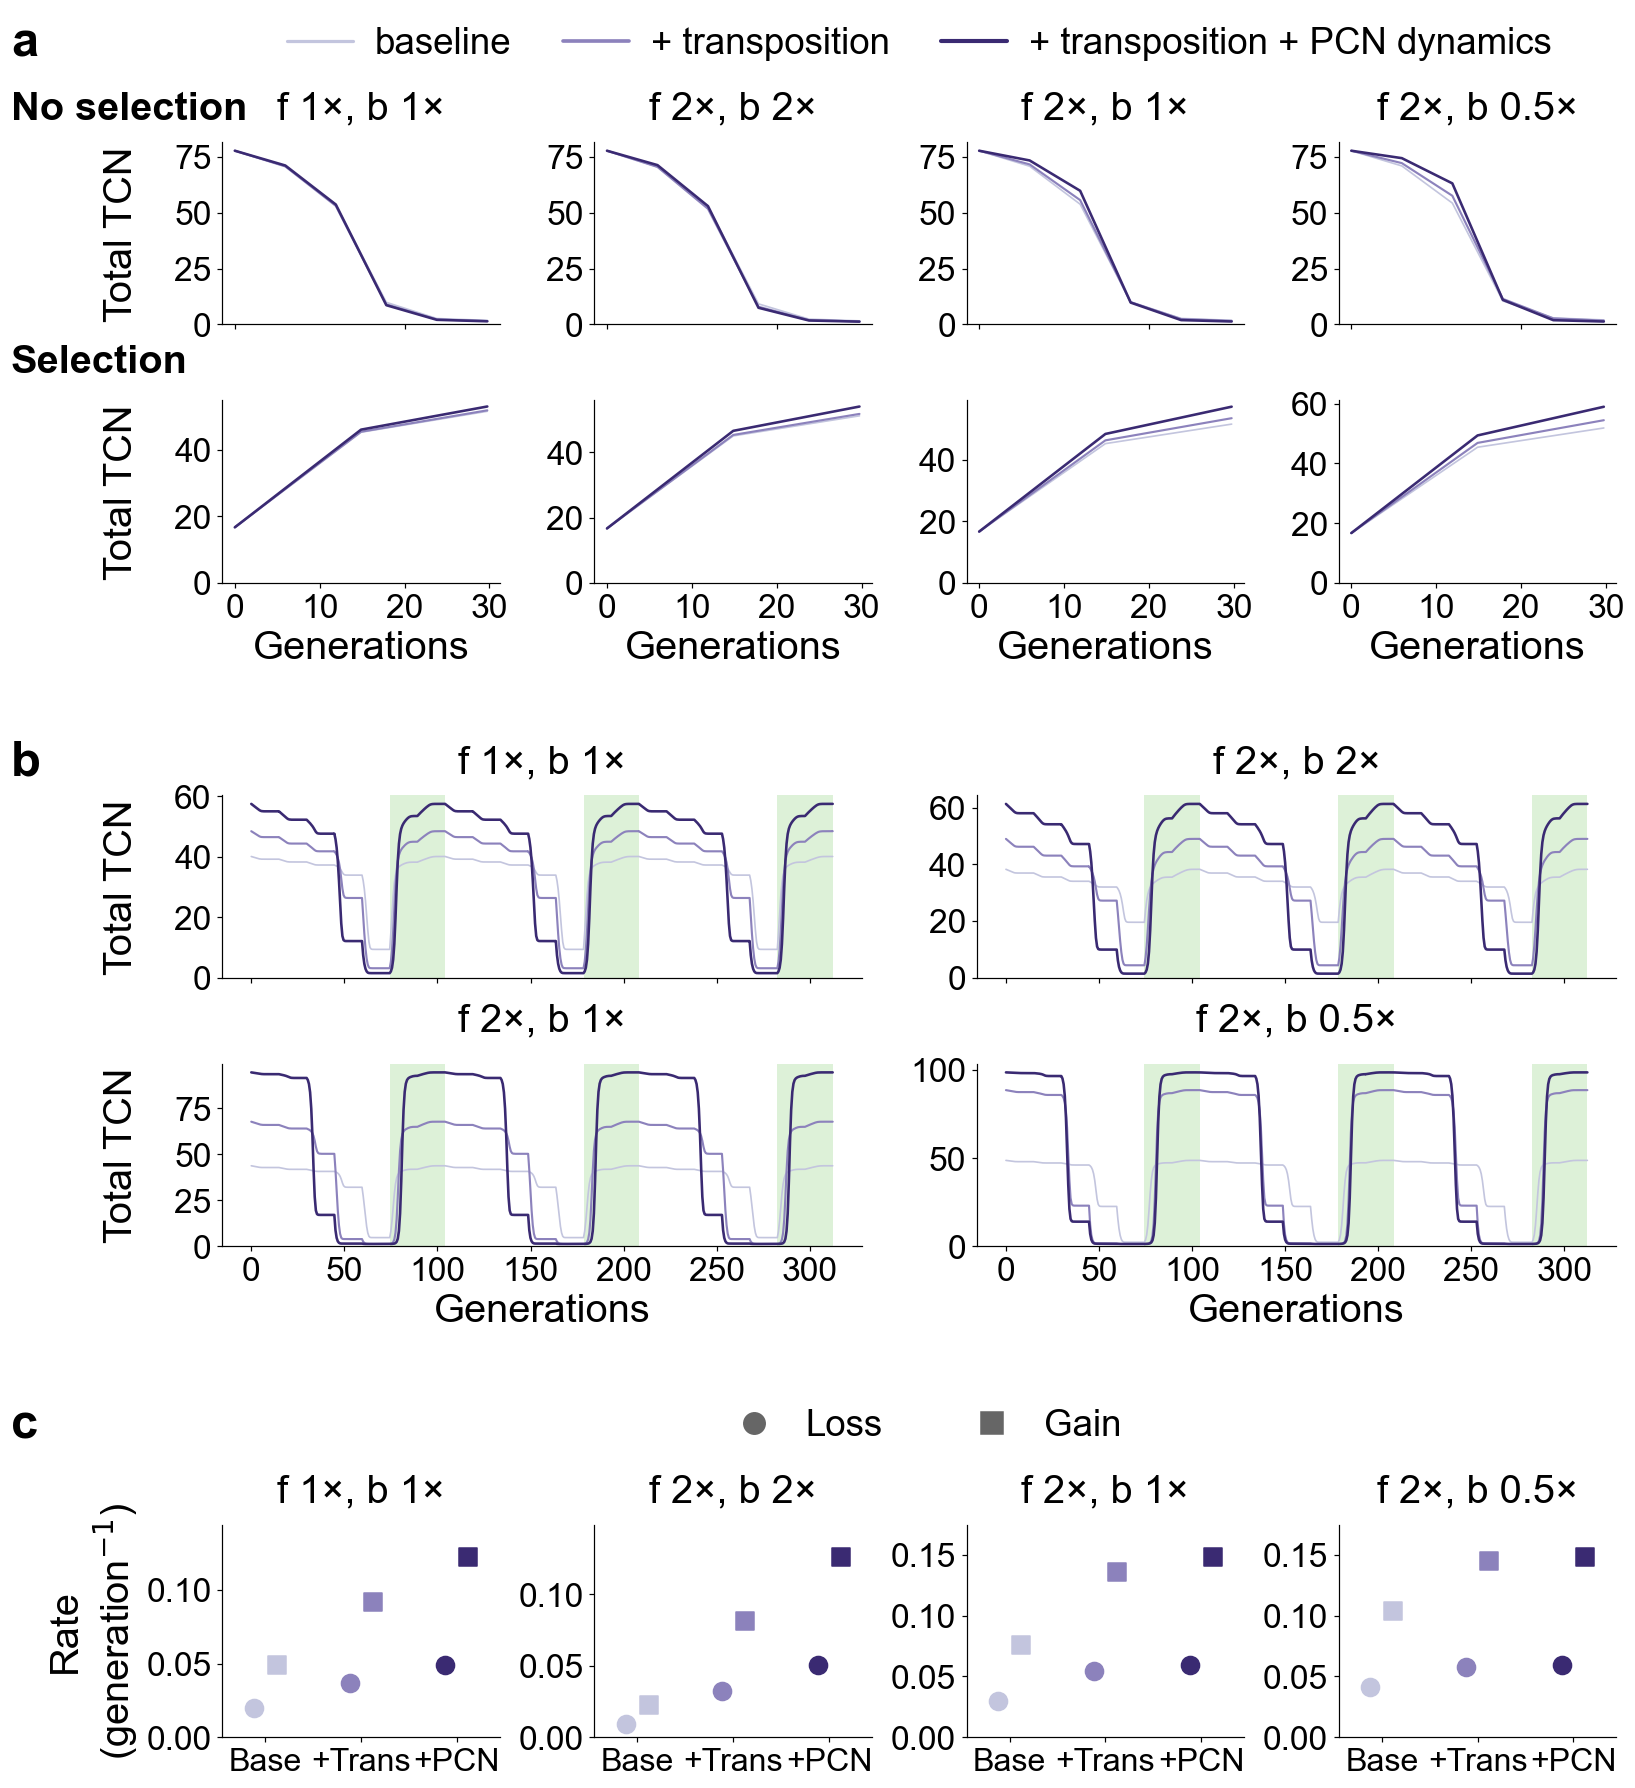

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

PANEL_FONT = 32
SECTION_FONT = 26
TITLE_FONT = 26
AXIS_FONT = 26
TICK_FONT = 22
LEGEND_FONT = 24
RATE_X_FONT = 21

FIG_W, FIG_H = 15.0, 16.7

ROWS = [
    ("a_head",   0.65),
    ("a_sub",    0.65),
    ("a_loss",   1.80),
    ("a_sel",    0.75),
    ("a_gain",   1.80),
    ("gap_ab",   1.45),
    ("b_head",   0.65),
    ("b_row1",   1.80),
    ("b_title2", 0.85),
    ("b_row2",   1.80),
    ("gap_bc",   1.45),
    ("c_head",   0.65),
    ("c_sub",    0.65),
    ("c_rate",   2.10),
]
ROW = {name: i for i, (name, _) in enumerate(ROWS)}

fig = plt.figure(figsize=(FIG_W, FIG_H))

master = fig.add_gridspec(
    len(ROWS), 1,
    height_ratios=[h for _, h in ROWS],
    left=0.14, right=0.985,
    bottom=0.05, top=0.99,
    hspace=0.0
)

WSPACE_4 = 0.34
WSPACE_2 = 0.18

def four_cols(row):
    return master[ROW[row]].subgridspec(1, 4, wspace=WSPACE_4)

def two_cols(row):
    return master[ROW[row]].subgridspec(1, 2, wspace=WSPACE_2)

def row_center_y(row):
    pos = master[ROW[row]].get_position(fig)
    return pos.y0 + pos.height / 2

def col_title(cell, text):
    t = fig.add_subplot(cell)
    t.axis("off")
    t.text(0.5, 0.5, text, transform=t.transAxes,
           ha="center", va="center", fontsize=TITLE_FONT)

def coef_label(sf, sb):
    return f"f {sf:g}×, b {sb:g}×"

PANEL_X = 0.012

loss_grid = four_cols("a_loss")
gain_grid = four_cols("a_gain")
a_sub_grid = four_cols("a_sub")

a_leg_ax = fig.add_subplot(master[ROW["a_head"]])
a_leg_ax.axis("off")
config_handles = [
    Line2D([0], [0], color=CONDITION_COLORS[k],
           lw=CONDITION_LINEWIDTHS[k] + 1.0, label=DISPLAY_LABELS[k])
    for k in CONFIG_ORDER
]
a_leg_ax.legend(
    handles=config_handles, loc="center", bbox_to_anchor=(0.5, 0.5),
    ncol=3, frameon=False, fontsize=LEGEND_FONT,
    handlelength=1.8, columnspacing=1.4, handletextpad=0.6,
    borderaxespad=0.0
)

for col, (_, sf, sb) in enumerate(COEFFICIENT_SETS):
    col_title(a_sub_grid[col], coef_label(sf, sb))

fixed_axes = []
for row, phase in enumerate(("loss", "gain")):
    grid = loss_grid if phase == "loss" else gain_grid
    row_axes = []
    for col, (label, sf, sb) in enumerate(COEFFICIENT_SETS):
        ax = fig.add_subplot(grid[col])
        row_axes.append(ax)

        for condition in CONFIG_ORDER:
            frame = R2_FIXED[(label, condition, phase)]
            v = (
                frame.loc[frame["passage_status"].isin(["phase_start", "pre_passage"])]
                .drop_duplicates("phase_day", keep="last")
                .sort_values("phase_day")
            )
            ax.plot(v["phase_day"] * PASSAGE_GENERATIONS, v["TCN_per_density"],
                    color=CONDITION_COLORS[condition],
                    lw=CONDITION_LINEWIDTHS[condition])

        if col == 0:
            ax.set_ylabel("Total TCN", fontsize=AXIS_FONT)
        if phase == "gain":
            ax.set_xlabel("Generations", fontsize=AXIS_FONT)
            ax.xaxis.set_major_locator(MultipleLocator(10))
        else:
            ax.tick_params(axis="x", labelbottom=False)

        ax.tick_params(labelsize=TICK_FONT)
        ax.set_ylim(bottom=0)
        ax.locator_params(axis="y", nbins=4)
    fixed_axes.append(row_axes)

b_rows = [two_cols("b_row1"), two_cols("b_row2")]
b_titles = [two_cols("b_head"), two_cols("b_title2")]

periodic_axes = []
for j, (label, sf, sb) in enumerate(COEFFICIENT_SETS):
    row, col = divmod(j, 2)
    col_title(b_titles[row][col], coef_label(sf, sb))

    ax = fig.add_subplot(b_rows[row][col])
    periodic_axes.append(ax)

    for cycle in range(1, ADDITIONAL_CYCLES_AFTER_CONVERGENCE + 1):
        left = ((cycle - 1) * DAYS_PER_CYCLE + RELAXED_DAYS_PER_CYCLE) * PASSAGE_GENERATIONS
        right = cycle * DAYS_PER_CYCLE * PASSAGE_GENERATIONS
        ax.axvspan(left, right, color=SELECTION_SHADE, lw=0, zorder=0)

    for condition in CONFIG_ORDER:
        if (label, condition) not in R2_PERIODIC:
            continue
        d = R2_PERIODIC[(label, condition)]
        ax.plot(d["Day"] * PASSAGE_GENERATIONS, d["TCN_per_density"],
                color=CONDITION_COLORS[condition],
                lw=CONDITION_LINEWIDTHS[condition], zorder=2)

    if col == 0:
        ax.set_ylabel("Total TCN", fontsize=AXIS_FONT)
    if row == 1:
        ax.set_xlabel("Generations", fontsize=AXIS_FONT)
    else:
        ax.tick_params(axis="x", labelbottom=False)

    ax.tick_params(labelsize=TICK_FONT)
    ax.set_ylim(bottom=0)
    ax.locator_params(axis="y", nbins=4)
    ax.xaxis.set_major_locator(MultipleLocator(50))

rate_grid = four_cols("c_rate")
c_sub_grid = four_cols("c_sub")

c_leg_ax = fig.add_subplot(master[ROW["c_head"]])
c_leg_ax.axis("off")
rate_handles = [
    Line2D([0], [0], marker=m, linestyle="None", color="0.40",
           markersize=14, label=lab)
    for m, lab in (("o", "Loss"), ("s", "Gain"))
]
c_leg_ax.legend(
    handles=rate_handles, loc="center", ncol=2, frameon=False,
    fontsize=LEGEND_FONT, columnspacing=2.0, handletextpad=0.4,
    borderaxespad=0.0
)

rate_axes = []
for j, (label, sf, sb) in enumerate(COEFFICIENT_SETS):
    col_title(c_sub_grid[j], coef_label(sf, sb))

    ax = fig.add_subplot(rate_grid[j])
    rate_axes.append(ax)

    ymax = 0.0
    for mi, (metric, marker) in enumerate((("loss_rate", "o"), ("gain_rate", "s"))):
        for ci, condition in enumerate(CONFIG_ORDER):
            d = R2_RATES.loc[
                (R2_RATES["coefficient_set"] == label)
                & (R2_RATES["condition"] == condition)
            ].iloc[0]
            value = float(d[metric]) if bool(d["response_valid"]) else np.nan
            if np.isfinite(value):
                ymax = max(ymax, value)
            ax.scatter(ci + (mi - 0.5) * 0.24, value, s=140, marker=marker,
                       color=CONDITION_COLORS[condition], zorder=3,
                       clip_on=False)

    ax.set_xticks(range(len(CONFIG_ORDER)))
    ax.set_xticklabels(["Base", "+Trans", "+PCN"], fontsize=RATE_X_FONT)
    ax.set_xlim(-0.45, len(CONFIG_ORDER) - 0.55)
    ax.set_ylim(0, ymax * 1.18 if ymax > 0 else 1)
    ax.locator_params(axis="y", nbins=4)
    ax.tick_params(axis="y", labelsize=TICK_FONT)

    if j == 0:
        ax.set_ylabel("Rate\n(generation$^{-1}$)", fontsize=AXIS_FONT)

all_axes = [ax for r in fixed_axes for ax in r] + periodic_axes + rate_axes
for ax in all_axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.align_ylabels([fixed_axes[0][0], fixed_axes[1][0],
                   periodic_axes[0], periodic_axes[2], rate_axes[0]])

def left_text(row, text, size, weight="bold"):
    fig.text(PANEL_X, row_center_y(row), text, fontsize=size,
             fontweight=weight, ha="left", va="center")

left_text("a_head", "a", PANEL_FONT)
left_text("a_sub", "No selection", SECTION_FONT)
left_text("a_sel", "Selection", SECTION_FONT)
left_text("b_head", "b", PANEL_FONT)
left_text("c_head", "c", PANEL_FONT)

save_figure(fig, "Extended_data_figure_2_coefficient_sensitivity_multipanel", FIGURE_DIR)
plt.show()